In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import xgboost as xgb

from matplotlib import pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.feature_selection import mutual_info_classif
from sklearn.feature_extraction import DictVectorizer
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import roc_auc_score
%matplotlib inline

# Loading Data 

In [6]:
df = pd.read_csv('data_airline_satisfaction.csv')
df

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,Male,disloyal Customer,34,Business travel,Business,526,3,3,3,1,...,4,4,3,2,4,4,4,0,0.0,False
129876,Male,Loyal Customer,23,Business travel,Business,646,4,4,4,4,...,4,4,4,5,5,5,4,0,0.0,True
129877,Female,Loyal Customer,17,Personal Travel,Eco,828,2,5,1,5,...,2,2,4,3,4,5,2,0,0.0,False
129878,Male,Loyal Customer,14,Business travel,Business,1127,3,3,3,3,...,4,4,3,2,5,4,4,0,0.0,True


# Exploratory Data Analysis (EDA)

## Step 1: Data Quality Check

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64  
 11  Online boarding                    1298

In [6]:
df.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True


In [16]:
categorical_features = []
for col in df.columns:
    if df[col].dtype == 'object':
        categorical_features.append(col)

print(f"Categorical Features: {categorical_features}")

Categorical Features: ['Gender', 'Customer Type', 'Type of Travel', 'Class']


In [17]:
numerical_features = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

ordinal_features = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness"
]

numerical_features = numerical_features + ordinal_features

In [18]:
df.describe().T.rename(columns={'50%': 'median'})

,count,mean,std,min,25%,median,75%,max
Age,129880.0,39.427957,15.119360,7.0,27.0,40.0,51.0,85.0
Flight Distance,129880.0,1190.316392,997.452477,31.0,414.0,844.0,1744.0,4983.0
Inflight wifi service,129880.0,2.728696,1.329340,0.0,2.0,3.0,4.0,5.0
Departure/Arrival time convenient,129880.0,3.057599,1.526741,0.0,2.0,3.0,4.0,5.0
Ease of Online booking,129880.0,2.756876,1.401740,0.0,2.0,3.0,4.0,5.0
Gate location,129880.0,2.976925,1.278520,0.0,2.0,3.0,4.0,5.0
Food and drink,129880.0,3.204774,1.329933,0.0,2.0,3.0,4.0,5.0
Online boarding,129880.0,3.252633,1.350719,0.0,2.0,3.0,4.0,5.0
Seat comfort,129880.0,3.441361,1.319289,0.0,2.0,4.0,5.0,5.0
Inflight entertainment,129880.0,3.358077,1.334049,0.0,2.0,4.0,4.0,5.0


In [19]:
# Check duplicates
print("Nb. of Duplicates:", df.duplicated().sum())

Nb. of Duplicates: 0


In [9]:
# Check NAs
print(df.isna().sum().sort_values(ascending=False))

Arrival Delay in Minutes             393
Gender                                 0
Customer Type                          0
Departure Delay in Minutes             0
Cleanliness                            0
Checkin service                        0
Baggage handling                       0
Leg room service                       0
On-board service                       0
Inflight entertainment                 0
Seat comfort                           0
Online boarding                        0
Food and drink                         0
Gate location                          0
Ease of Online booking                 0
Departure/Arrival time convenient      0
Inflight wifi service                  0
Flight Distance                        0
Class                                  0
Type of Travel                         0
Age                                    0
satisfaction                           0
dtype: int64


In [10]:
df["Arrival Delay in Minutes"].median()

0.0

In [7]:
df["Arrival Delay in Minutes"] = df["Arrival Delay in Minutes"].fillna(df["Arrival Delay in Minutes"].median())

## Step 2: Target Distribution

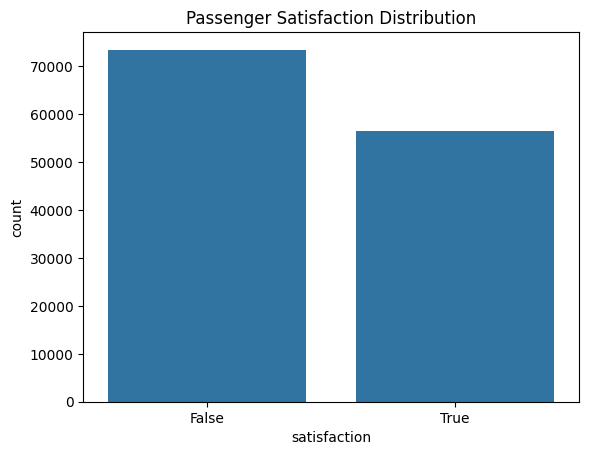

False    56.553742
True     43.446258
Name: satisfaction, dtype: float64


In [44]:
sns.countplot(data=df, x="satisfaction")
plt.title("Passenger Satisfaction Distribution")
plt.show()

print(df["satisfaction"].value_counts(normalize=True) * 100)

## Step 3: Numerical Feature Distributions

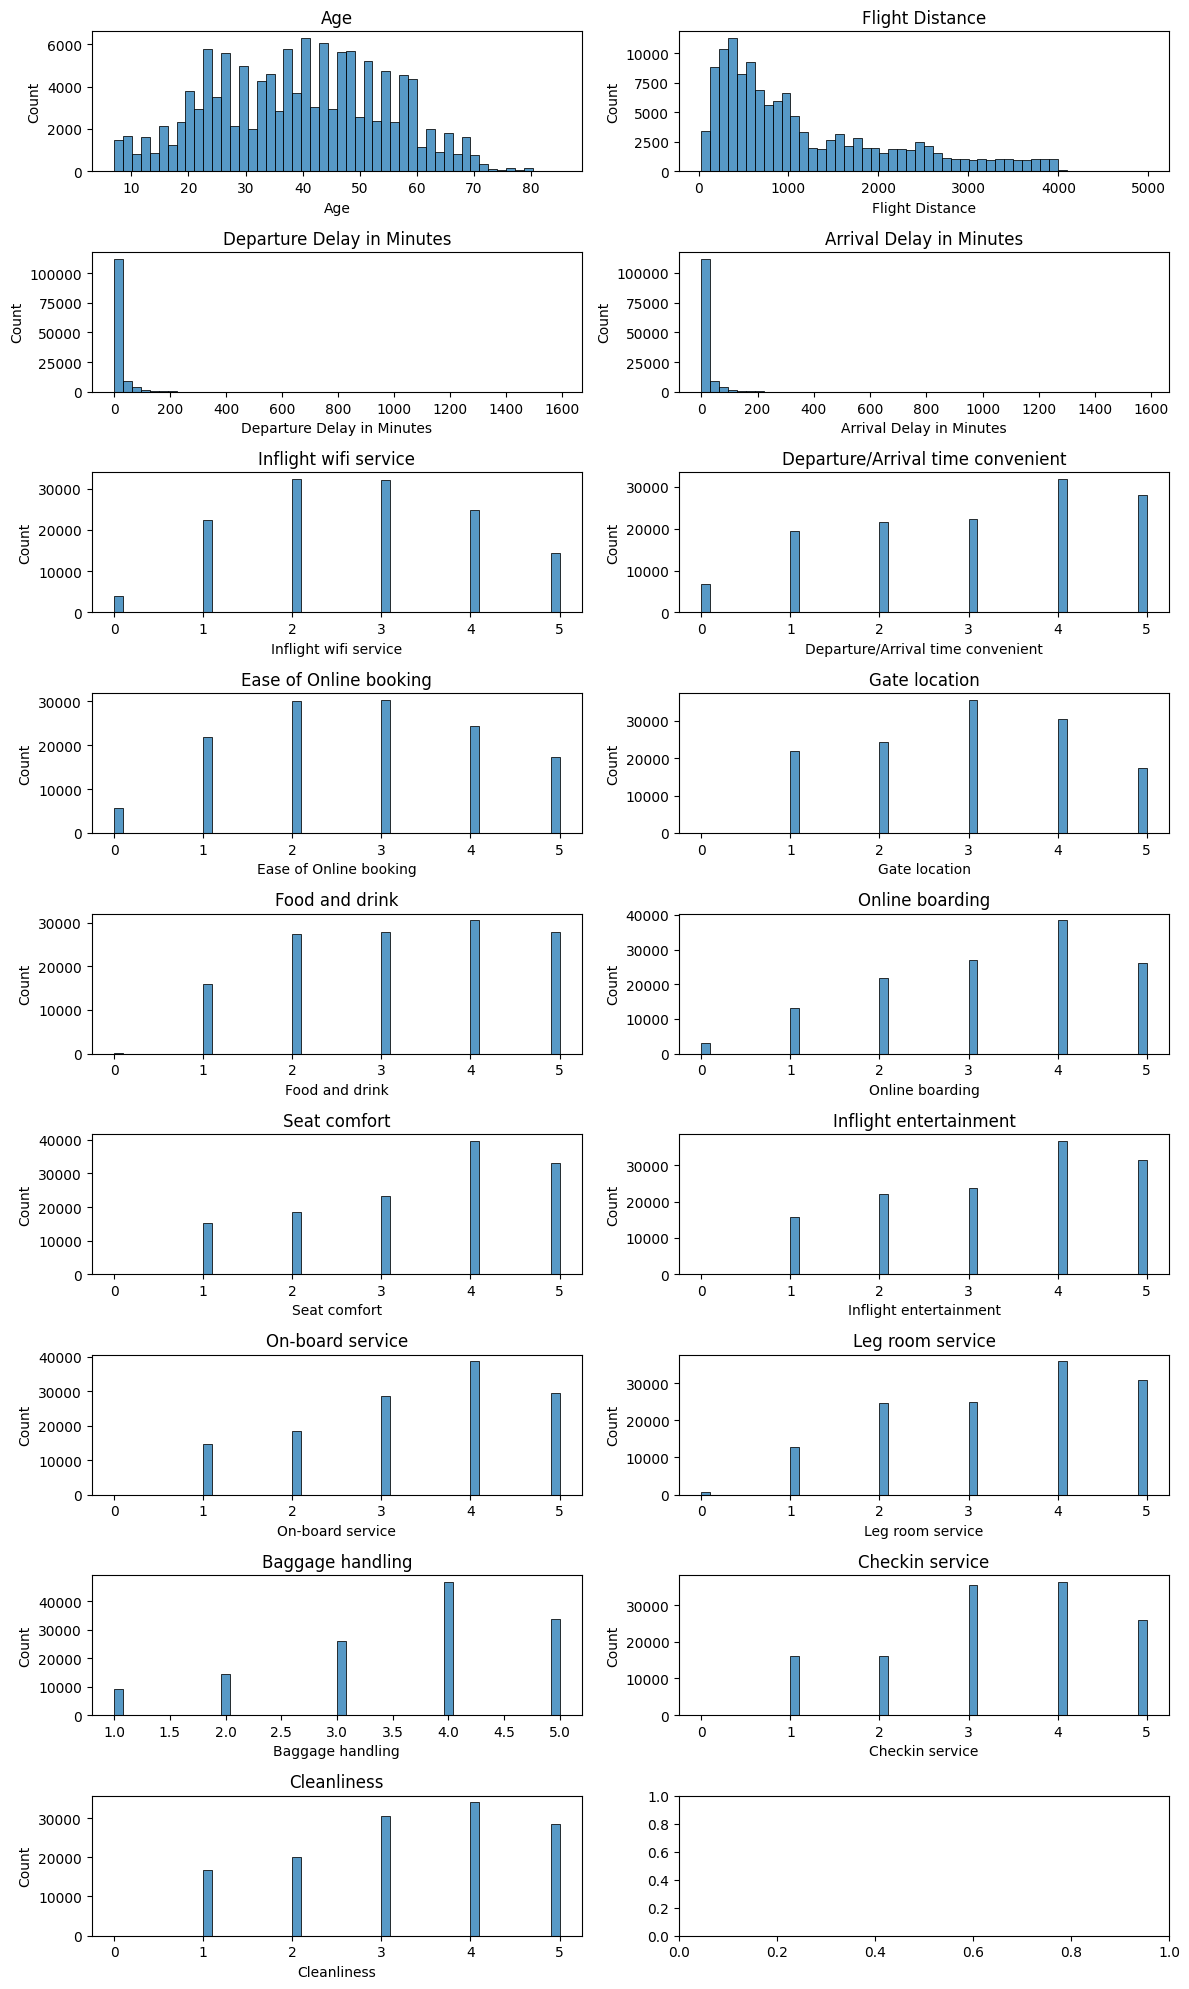

In [20]:
fig, axes = plt.subplots(int(len(numerical_features)/2)+1, 2, figsize=(12, 20))
for ax, col in zip(axes.flat, numerical_features):
    sns.histplot(df[col], bins=50, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.show()

## Step 5: Feature vs. Target

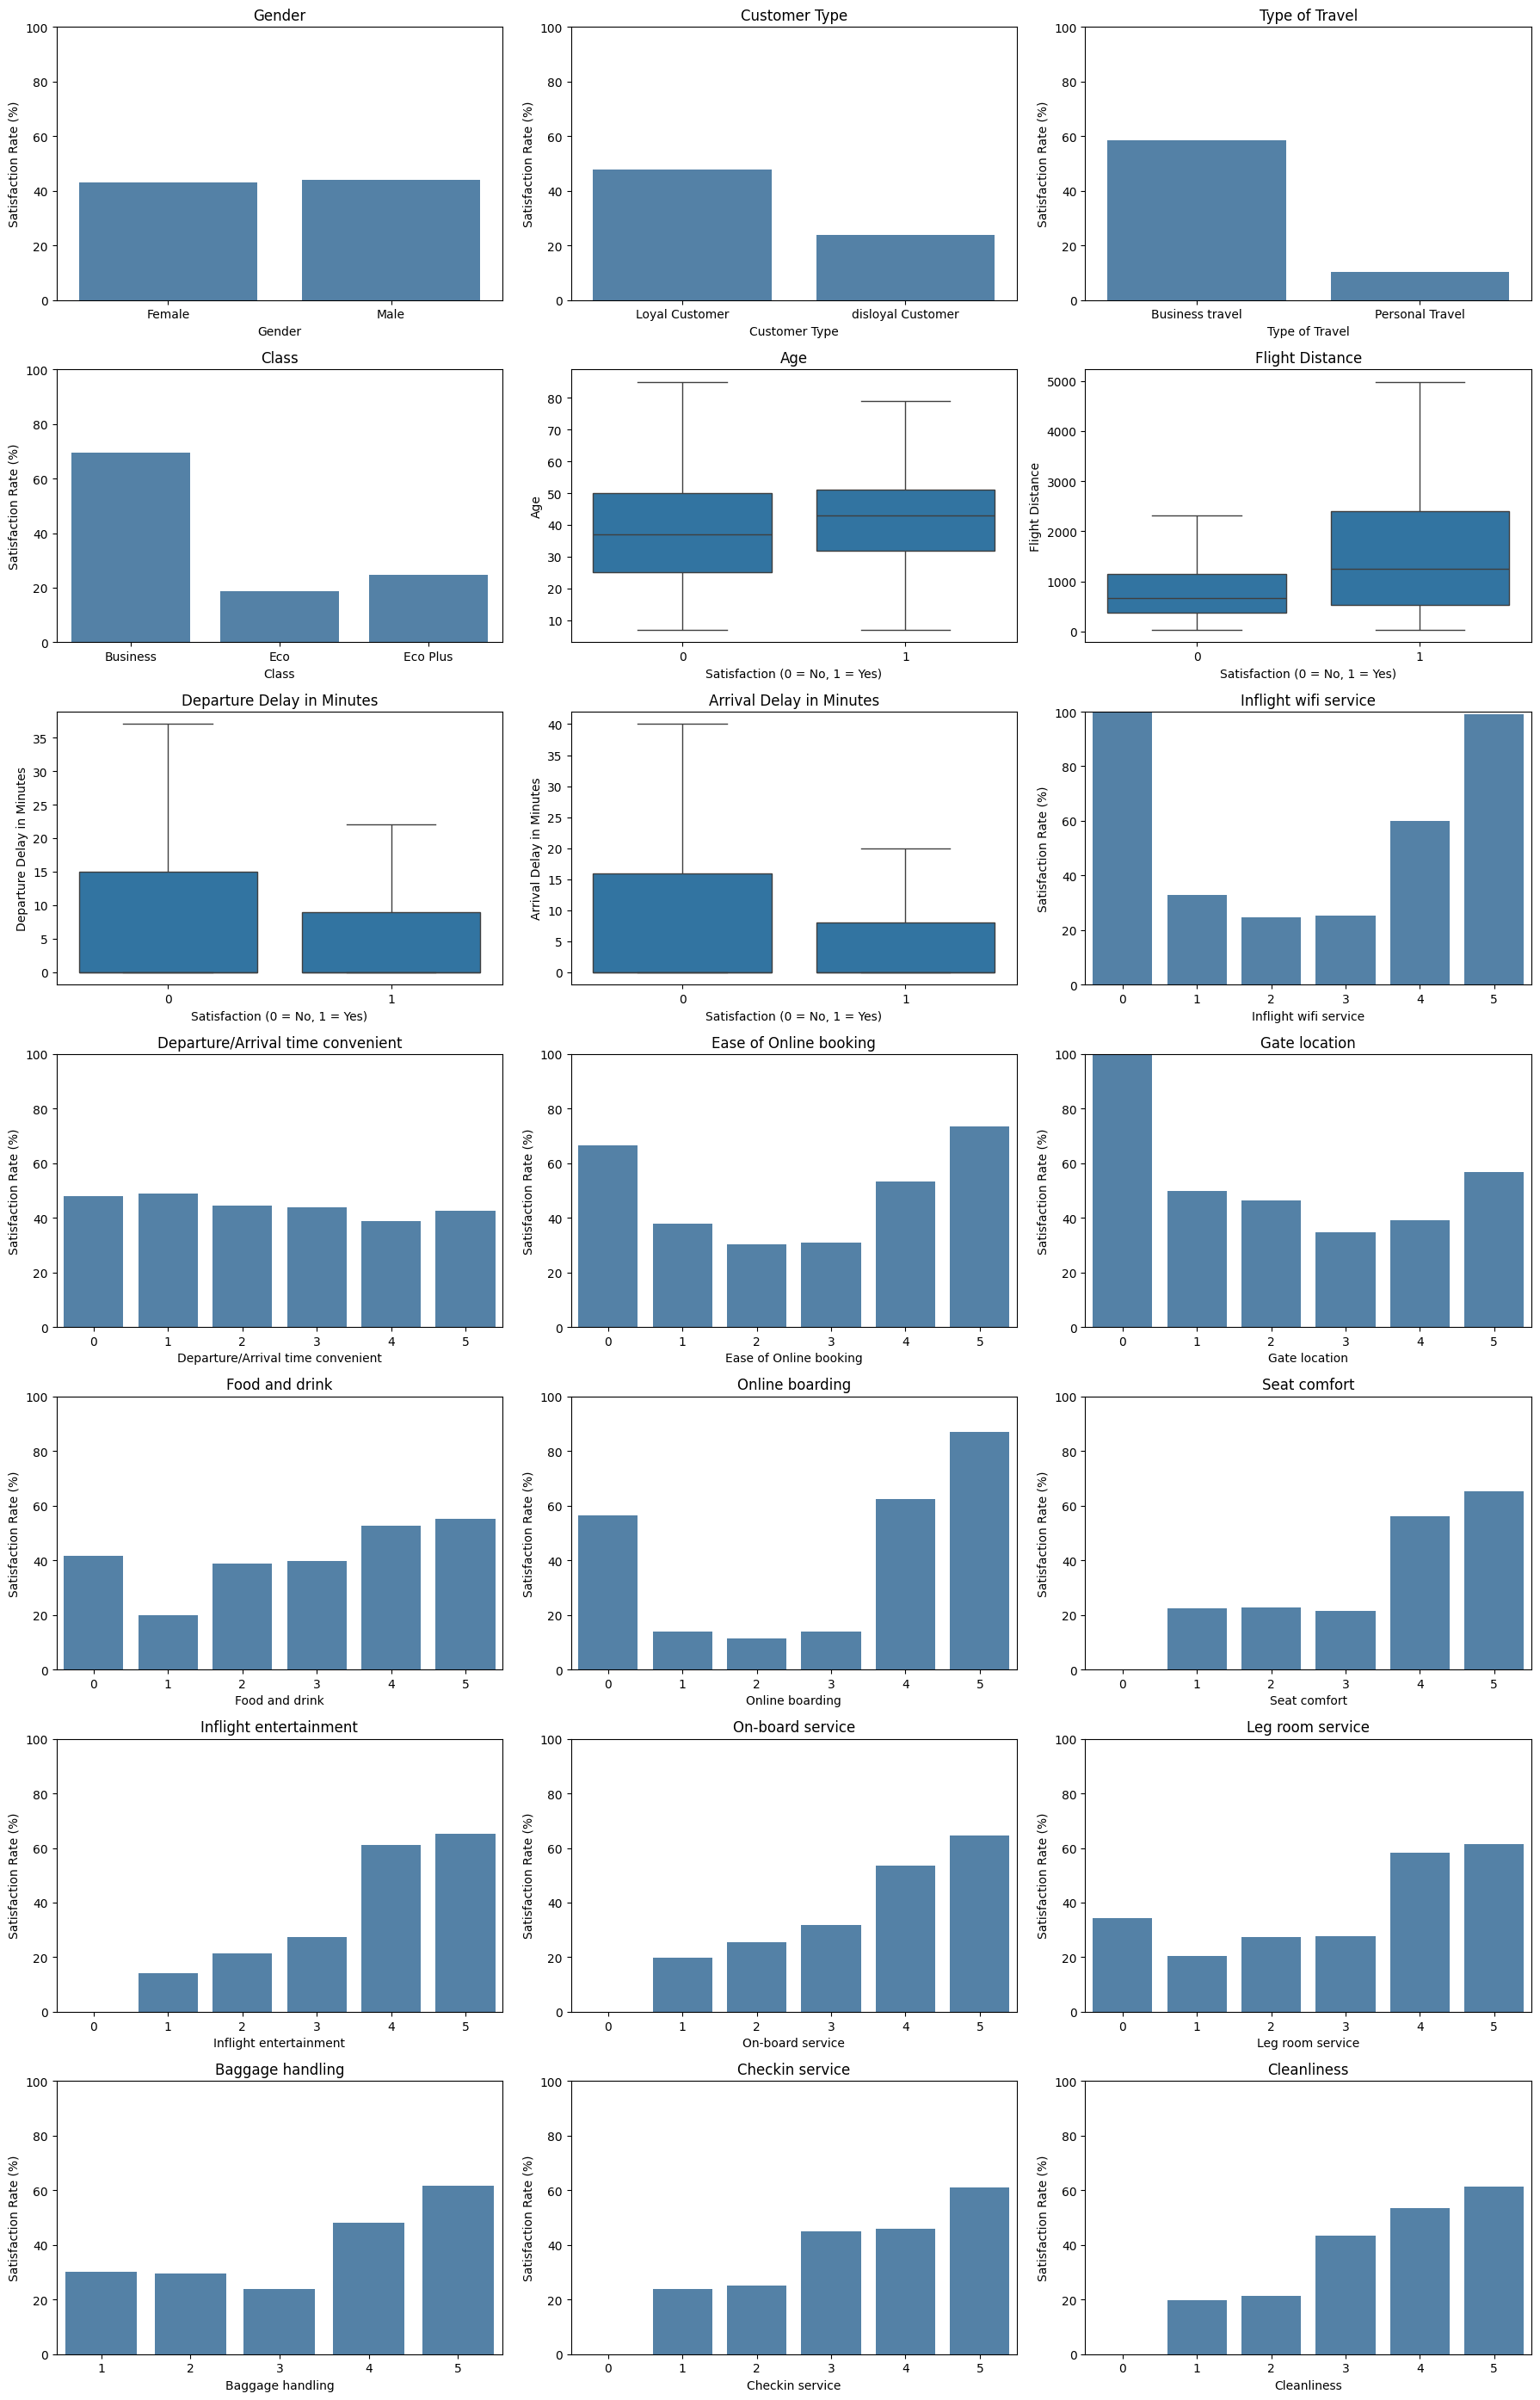

In [62]:
target = "satisfaction"

# Make sure target is 0/1
df_plot = df.copy()
df_plot[target] = df_plot[target].astype(int)

features = (categorical_features + numerical_features)

ncols = 3
nrows = int(np.ceil(len(features) / ncols))

fig, axes = plt.subplots(
    nrows, ncols,
    figsize=(18, nrows * 4)
)

axes = axes.flatten()

for i, col in enumerate(features):
    ax = axes[i]

    if col in categorical_features + ordinal_features:
        # Satisfaction rate per feature value
        rates = (
            df_plot.groupby(col)[target]
            .mean()
            .mul(100)
            .reset_index()
        )

        sns.barplot(
            data=rates,
            x=col,
            y=target,
            ax=ax,
            color="steelblue"
        )

        ax.set_ylabel("Satisfaction Rate (%)")
        ax.set_ylim(0, 100)

    else:
        # Distribution by satisfaction
        sns.boxplot(
            data=df_plot,
            x=target,
            y=col,
            ax=ax,
            showfliers=False
        )

        ax.set_xlabel("Satisfaction (0 = No, 1 = Yes)")

    ax.set_title(col)

# Remove unused subplots
for j in range(len(features), len(axes)):
    fig.delaxes(axes[j])

plt.tight_layout()
plt.show()

### Train, Val and Test 

In [21]:
df.head(5)

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True


In [22]:
df_train_full, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_train_full, test_size=0.25, random_state=1)
df_train_full = df_train_full.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = (df_train.satisfaction == True).astype(int).values
y_val = (df_val.satisfaction == True).astype(int).values
y_test = (df_test.satisfaction == True).astype(int).values

del df_train['satisfaction']
del df_val['satisfaction']
del df_test['satisfaction']

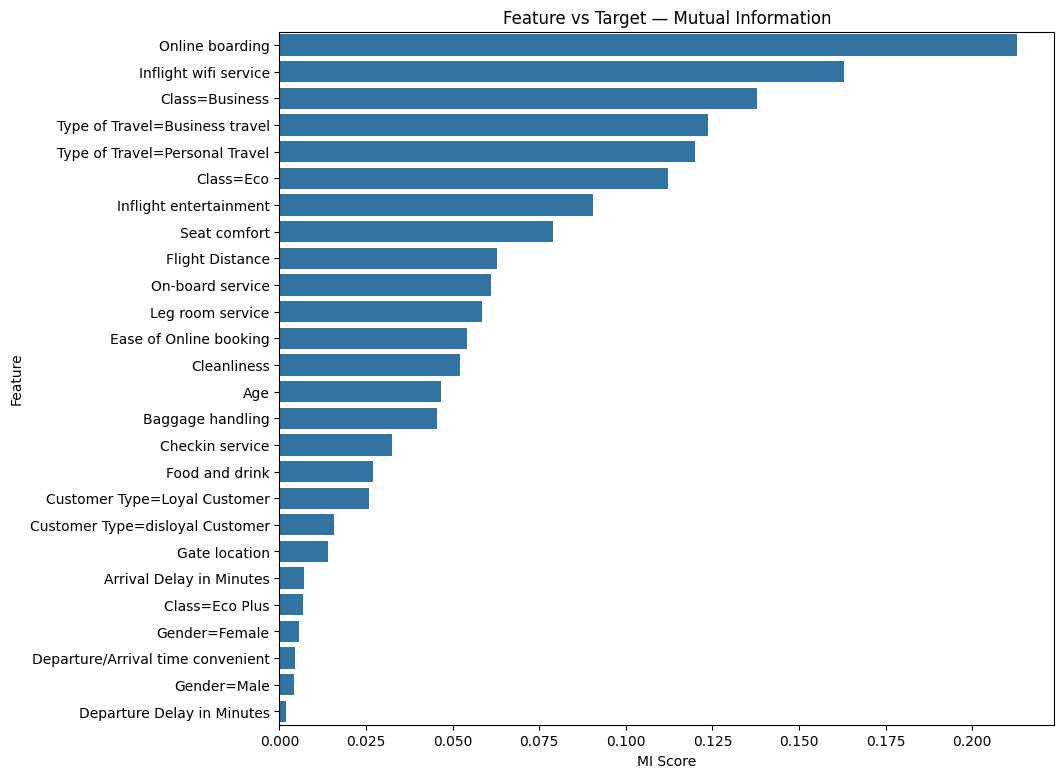

In [23]:
dv = DictVectorizer(sparse=False)

X_train = dv.fit_transform(df_train.to_dict(orient="records"))
X_val = dv.transform(df_val.to_dict(orient="records"))
X_test = dv.transform(df_test.to_dict(orient="records"))

mi_scores = mutual_info_classif(X_train, y_train, random_state=1)

mi_df = pd.DataFrame({"Feature": dv.get_feature_names_out(),
                      "MI Score": mi_scores
                     }).sort_values("MI Score", ascending=False)

plt.figure(figsize=(10, 9))
sns.barplot(data=mi_df,
            x="MI Score",
            y="Feature")
plt.title("Feature vs Target — Mutual Information")
plt.show()

### Selective feature engineering (a not_rated indicator)

In [82]:
zero_analysis = []
for col in ordinal_features:
    not_rated = df[col] == 0

    zero_analysis.append({
        "Feature": col,
        "Not Rated Count": not_rated.sum(),
        "Not Rated %": not_rated.mean() * 100,
        "Satisfaction % (Not Rated)": (df.loc[not_rated, "satisfaction"].mean() * 100) if not_rated.any() else np.nan,
        "Satisfaction % (Rated)": (df.loc[~not_rated, "satisfaction"].mean() * 100) if (~not_rated).any() else np.nan
    })

zero_df = pd.DataFrame(zero_analysis)
zero_df['Satisfaction Gap'] = zero_df['Satisfaction % (Not Rated)'] - zero_df['Satisfaction % (Rated)']

zero_df = zero_df.sort_values("Satisfaction Gap", ascending=False).reset_index(drop=True)
zero_df

,Feature,Not Rated Count,Not Rated %,Satisfaction % (Not Rated),Satisfaction % (Rated),Satisfaction Gap
0,Inflight wifi service,3916,3.015091,99.744637,41.696040,58.048597
1,Gate location,1,0.000770,100.000000,43.445823,56.554177
2,Ease of Online booking,5682,4.374808,66.561070,42.388766,24.172304
3,Online boarding,3080,2.371420,56.461039,43.130126,13.330913
4,Departure/Arrival time convenient,6681,5.143979,48.106571,43.193532,4.913038
5,Food and drink,132,0.101632,41.666667,43.448069,-1.781402
6,Leg room service,598,0.460425,34.448161,43.487879,-9.039719
7,Seat comfort,1,0.000770,0.000000,43.446593,-43.446593
8,Checkin service,1,0.000770,0.000000,43.446593,-43.446593
9,On-board service,5,0.003850,0.000000,43.447931,-43.447931


In [88]:
features_not_rated_indicator = []
for idx in range(len(zero_df)):
    if zero_df["Satisfaction Gap"].iloc[idx] > 0:
        features_not_rated_indicator.append(zero_df["Feature"].iloc[idx])

features_not_rated_indicator

['Inflight wifi service',
 'Gate location',
 'Ease of Online booking',
 'Online boarding',
 'Departure/Arrival time convenient']

In [93]:
def add_not_rated_features(X, not_rated_features):
    X = X.copy()

    indicators = X[not_rated_features].eq(0).astype("int8")

    indicators.columns = [
        f"{col}_not_rated"
        for col in not_rated_features
    ]

    return pd.concat([X, indicators], axis=1)

#df_train = add_not_rated_features(df_train, features_not_rated_indicator)
#df_val = add_not_rated_features(df_val, features_not_rated_indicator)
#df_test = add_not_rated_features(df_test, features_not_rated_indicator)

#X_train = dv.fit_transform(df_train.to_dict(orient="records"))
#X_val = dv.transform(df_val.to_dict(orient="records"))
#X_test = dv.transform(df_test.to_dict(orient="records"))

In [94]:
wifi_zero = df["Inflight wifi service"] == 0

print(
    pd.crosstab(
        df.loc[wifi_zero, "Class"],
        df.loc[wifi_zero, "satisfaction"],
        normalize="index"
    )
)

print(
    pd.crosstab(
        df.loc[wifi_zero, "Type of Travel"],
        df.loc[wifi_zero, "satisfaction"],
        normalize="index"
    )
)

satisfaction     False      True
Class                           
Business      0.000000  1.000000
Eco           0.003422  0.996578
Eco Plus      0.023346  0.976654
satisfaction        False      True
Type of Travel                     
Business travel  0.003214  0.996786
Personal Travel  0.000000  1.000000


## Step 6: Modelling

In [98]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features)
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)
dtrain

In [123]:
df_scores_xgb = pd.DataFrame(columns=['eta', 'max_depth', 'min_child_weight', 'rmse'])
scores_xgb = []
scores = {}
watchlist = [(dtrain, 'train'), (dval, 'val')]
for eta in [0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0]:
    for m in [1, 3, 5, 10, 15, 20, None]:
        for c in [1, 5, 10, 50, 100]:
            xgb_params = {
                'eta': eta,
                'max_depth': m,
                'min_child_weight': c,
                'objective': 'binary:logistic',
                'eval_metric': 'auc',
                'nthread': 8,
                'seed': 1,
                'verbosity': 1
            }
        
            evals_result = {}
            model = xgb.train(
                xgb_params,
                dtrain,
                num_boost_round=100,
                evals=watchlist,
                evals_result=evals_result,
                verbose_eval=False
            )
        
            scores[eta] = evals_result['val']['auc']
        
            print(f"eta={eta!s:<5} & max_depth={m!s:<5} & min_child_weight={c!s:<5} >>> RMSE={scores[eta][-1]:.4f}")
            
            scores_xgb.append({
                'eta': eta,
                'max_depth': m,
                'min_child_weight': c,
                'auc': scores[eta]
            })
            
df_scores_xgb = (pd.DataFrame(scores_xgb, columns=['eta', 'max_depth', 'min_child_weight', 'auc'])
                 .sort_values('auc', ascending=False)
                .reset_index(drop=True)
)

display(df_scores_xgb.head(10))

eta=0.01  & max_depth=1     & min_child_weight=1     >>> RMSE=0.9084
eta=0.01  & max_depth=1     & min_child_weight=5     >>> RMSE=0.9084
eta=0.01  & max_depth=1     & min_child_weight=10    >>> RMSE=0.9084
eta=0.01  & max_depth=1     & min_child_weight=50    >>> RMSE=0.9084
eta=0.01  & max_depth=1     & min_child_weight=100   >>> RMSE=0.9084
eta=0.01  & max_depth=3     & min_child_weight=1     >>> RMSE=0.9669
eta=0.01  & max_depth=3     & min_child_weight=5     >>> RMSE=0.9669
eta=0.01  & max_depth=3     & min_child_weight=10    >>> RMSE=0.9669
eta=0.01  & max_depth=3     & min_child_weight=50    >>> RMSE=0.9669
eta=0.01  & max_depth=3     & min_child_weight=100   >>> RMSE=0.9669
eta=0.01  & max_depth=5     & min_child_weight=1     >>> RMSE=0.9784
eta=0.01  & max_depth=5     & min_child_weight=5     >>> RMSE=0.9783
eta=0.01  & max_depth=5     & min_child_weight=10    >>> RMSE=0.9783
eta=0.01  & max_depth=5     & min_child_weight=50    >>> RMSE=0.9773
eta=0.01  & max_depth=5     & min_

,eta,max_depth,min_child_weight,auc
0,0.01,20.0,1,"[0.9909473634213897, 0.9909269090578564, 0.990..."
1,0.50,20.0,1,"[0.9909442984313037, 0.9918487869510624, 0.992..."
2,0.30,20.0,1,"[0.9909442984313037, 0.9914924283593979, 0.992..."
3,1.00,20.0,1,"[0.9909442984313037, 0.9914502508409585, 0.991..."
4,0.20,20.0,1,"[0.9909442984313037, 0.9913909160083015, 0.992..."
5,0.10,20.0,1,"[0.9909442984313037, 0.9912191951920702, 0.991..."
6,0.05,20.0,1,"[0.9909442984313037, 0.991212902469062, 0.9912..."
7,0.50,15.0,1,"[0.9908831764412024, 0.9920444339780039, 0.992..."
8,1.00,15.0,1,"[0.9908831764412024, 0.9918009074058358, 0.992..."
9,0.30,15.0,1,"[0.9908831764412024, 0.9915711747959325, 0.992..."


# Feature Eng. & Model Selection

In [46]:
df = pd.read_csv('data_airline_satisfaction.csv')
df["Arrival Delay in Minutes"] = df["Arrival Delay in Minutes"].fillna(df["Arrival Delay in Minutes"].median())

df_train_full, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_train_full, test_size=0.25, random_state=1)
df_train_full = df_train_full.reset_index(drop=True)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = (df_train.satisfaction == True).astype(int).values
y_val = (df_val.satisfaction == True).astype(int).values
y_test = (df_test.satisfaction == True).astype(int).values

del df_train['satisfaction']
del df_val['satisfaction']
del df_test['satisfaction']

In [23]:
df_train.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
0,Female,Loyal Customer,20,Personal Travel,Eco Plus,533,3,4,3,2,...,3,1,5,5,3,4,3,5,42,24.0
1,Female,Loyal Customer,17,Personal Travel,Eco,1660,3,0,3,1,...,3,2,2,5,4,5,3,2,8,0.0
2,Female,disloyal Customer,33,Business travel,Business,565,3,3,3,4,...,3,1,1,2,4,4,2,1,12,5.0
3,Male,Loyal Customer,34,Personal Travel,Business,916,1,4,1,3,...,5,4,3,3,1,3,4,5,22,0.0
4,Female,Loyal Customer,62,Personal Travel,Eco,280,1,5,1,2,...,5,4,4,4,1,4,4,4,0,0.0


In [24]:
rating_cols = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness"
]

digital_cols = [
    "Inflight wifi service",
    "Ease of Online booking",
    "Online boarding"
]

comfort_cols = [
    "Seat comfort",
    "Leg room service",
    "Food and drink",
    "Cleanliness",
    "Inflight entertainment"
]

staff_cols = [
    "On-board service",
    "Checkin service",
    "Baggage handling"
]

not_rated_cols = [
    "Inflight wifi service",
    "Ease of Online booking",
    "Online boarding",
    "Departure/Arrival time convenient"
]


def feature_engineering(X):
    X = X.copy()

    # A. Service ratings
    # Zero means Not Rated, not dissatisfaction
    ratings = X[rating_cols].replace(0, np.nan)

    X["service_mean"] = ratings.mean(axis=1)
    X["service_min"] = ratings.min(axis=1)
    X["service_std"] = ratings.std(axis=1).fillna(0)

    X["low_rating_count"] = ratings.le(2).sum(axis=1)
    X["high_rating_count"] = ratings.ge(4).sum(axis=1)
    X["rated_service_count"] = ratings.notna().sum(axis=1)

    # Group-specific scores
    X["digital_service_mean"] = ratings[digital_cols].mean(axis=1)
    X["comfort_mean"] = ratings[comfort_cols].mean(axis=1)
    X["staff_service_mean"] = ratings[staff_cols].mean(axis=1)

    # Difference between experience dimensions
    X["comfort_vs_digital"] = (
        X["comfort_mean"] - X["digital_service_mean"]
    )

    # B. Not-rated features
    for col in not_rated_cols:
        X[f"{col}_not_rated"] = X[col].eq(0).astype("int8")

    # C. Delay features
    dep = X["Departure Delay in Minutes"]
    arr = X["Arrival Delay in Minutes"]

    X["arrival_delay_missing"] = arr.isna().astype("int8")

    # Original chosen imputation: zero
    arr = arr.fillna(0)
    X["Arrival Delay in Minutes"] = arr

    X["total_delay"] = dep + arr
    X["delay_difference"] = arr - dep

    X["delay_recovered"] = (
        (dep > arr) & (dep > 0)
    ).astype("int8")

    X["delayed_over_30"] = (
        (dep > 30) | (arr > 30)
    ).astype("int8")

    X["delayed_over_60"] = (
        (dep > 60) | (arr > 60)
    ).astype("int8")

    # D. Passenger profile interactions
    X["class_travel"] = (
        X["Class"].astype(str)
        + "_"
        + X["Type of Travel"].astype(str)
    )

    X["class_customer"] = (
        X["Class"].astype(str)
        + "_"
        + X["Customer Type"].astype(str)
    )

    # E. Fill derived missing aggregates
    derived_cols = [
        "service_mean",
        "service_min",
        "digital_service_mean",
        "comfort_mean",
        "staff_service_mean",
        "comfort_vs_digital"
    ]

    X[derived_cols] = X[derived_cols].fillna(-1)

    return X

In [25]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
import xgboost as xgb

# Feature engineering
X_train_fe = feature_engineering(df_train)
X_val_fe = feature_engineering(df_val)

# Encoding
dv = DictVectorizer(sparse=True)

train_dicts = X_train_fe.to_dict(orient="records")
val_dicts = X_val_fe.to_dict(orient="records")

X_train_enc = dv.fit_transform(train_dicts)
X_val_enc = dv.transform(val_dicts)

# XGBoost matrices
dtrain_fe = xgb.DMatrix(
    X_train_enc,
    label=y_train,
    feature_names=dv.get_feature_names_out().tolist()
)

dval_fe = xgb.DMatrix(
    X_val_enc,
    label=y_val,
    feature_names=dv.get_feature_names_out().tolist()
)

params = {
    "eta": 0.05,
    "max_depth": 5,
    "min_child_weight": 5,
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "tree_method": "hist",
    "nthread": 8,
    "seed": 1
}

model_fe = xgb.train(
    params,
    dtrain_fe,
    num_boost_round=500,
    evals=[(dval_fe, "val")],
    early_stopping_rounds=30,
    verbose_eval=False
)

y_pred = model_fe.predict(
    dval_fe,
    iteration_range=(0, model_fe.best_iteration + 1)
)

print(f"Validation AUC: {roc_auc_score(y_val, y_pred):.5f}")
print(f"Best iteration: {model_fe.best_iteration}")

Validation AUC: 0.99434
Best iteration: 499


In [32]:
eta_lst = [0.01, 0.05, 0.1, 0.2, 0.3, 0.5, 1.0]
max_depth_lst = [1, 3, 5, 10, 15, 20, None]
min_child_weight_lst = [1, 5, 10, 50, 100]

for e in eta_lst:
    for m in max_depth_lst:
        for c in min_child_weight_lst:
            params = {
                "eta": e,
                "max_depth": m,
                "min_child_weight": c,
                "objective": "binary:logistic",
                "eval_metric": "auc",
                "tree_method": "hist",
                "nthread": 8,
                "seed": 1
            }
            
            model_fe = xgb.train(
                params,
                dtrain_fe,
                num_boost_round=500,
                evals=[(dval_fe, "val")],
                early_stopping_rounds=30,
                verbose_eval=False
            )
            
            y_pred = model_fe.predict(
                dval_fe,
                iteration_range=(0, model_fe.best_iteration + 1)
            )

            print(f"eta={e!s:<5} & max_depth={m!s:<5} & min_child_weight={c!s:<5}")
            print(f"Validation AUC: {roc_auc_score(y_val, y_pred):.5f}")
            print(f"Best iteration: {model_fe.best_iteration}")
            print()

eta=0.01  & max_depth=1     & min_child_weight=1    
Validation AUC: 0.87744
Best iteration: 14

eta=0.01  & max_depth=1     & min_child_weight=5    
Validation AUC: 0.87744
Best iteration: 14

eta=0.01  & max_depth=1     & min_child_weight=10   
Validation AUC: 0.87744
Best iteration: 14

eta=0.01  & max_depth=1     & min_child_weight=50   
Validation AUC: 0.87744
Best iteration: 14

eta=0.01  & max_depth=1     & min_child_weight=100  
Validation AUC: 0.87744
Best iteration: 14

eta=0.01  & max_depth=3     & min_child_weight=1    
Validation AUC: 0.98400
Best iteration: 499

eta=0.01  & max_depth=3     & min_child_weight=5    
Validation AUC: 0.98399
Best iteration: 499

eta=0.01  & max_depth=3     & min_child_weight=10   
Validation AUC: 0.98398
Best iteration: 499

eta=0.01  & max_depth=3     & min_child_weight=50   
Validation AUC: 0.98386
Best iteration: 499

eta=0.01  & max_depth=3     & min_child_weight=100  
Validation AUC: 0.98360
Best iteration: 499

eta=0.01  & max_depth=5  

In [26]:
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
import xgboost as xgb

# Feature engineering
X_train_fe = feature_engineering(df_train)
X_val_fe = feature_engineering(df_val)

# Encoding
dv = DictVectorizer(sparse=True)

train_dicts = X_train_fe.to_dict(orient="records")
val_dicts = X_val_fe.to_dict(orient="records")

X_train_enc = dv.fit_transform(train_dicts)
X_val_enc = dv.transform(val_dicts)

# XGBoost matrices
dtrain_fe = xgb.DMatrix(
    X_train_enc,
    label=y_train,
    feature_names=dv.get_feature_names_out().tolist()
)

dval_fe = xgb.DMatrix(
    X_val_enc,
    label=y_val,
    feature_names=dv.get_feature_names_out().tolist()
)

params = {
    "eta": 0.1,
    "max_depth": 10,
    "min_child_weight": 5,
    "objective": "binary:logistic",
    "eval_metric": "auc",
    "tree_method": "hist",
    "nthread": 8,
    "seed": 1
}

model_fe = xgb.train(
    params,
    dtrain_fe,
    num_boost_round=500,
    evals=[(dval_fe, "val")],
    early_stopping_rounds=30,
    verbose_eval=False
)

y_pred = model_fe.predict(
    dval_fe,
    iteration_range=(0, model_fe.best_iteration + 1)
)

print(f"Validation AUC: {roc_auc_score(y_val, y_pred):.5f}")
print(f"Best iteration: {model_fe.best_iteration}")

Validation AUC: 0.99505
Best iteration: 141


In [34]:
import pickle

model_filename = 'model_xgboost.bin'

with open(model_filename, 'wb') as f_out:
    pickle.dump((dv, model_fe), f_out)

In [2]:
print(xgb.__version__)

2.1.4


In [52]:
print(df_test.iloc[2].to_dict())

{'Gender': 'Male', 'Customer Type': 'Loyal Customer', 'Age': 56, 'Type of Travel': 'Business travel', 'Class': 'Business', 'Flight Distance': 600, 'Inflight wifi service': 2, 'Departure/Arrival time convenient': 1, 'Ease of Online booking': 2, 'Gate location': 2, 'Food and drink': 3, 'Online boarding': 4, 'Seat comfort': 4, 'Inflight entertainment': 4, 'On-board service': 4, 'Leg room service': 4, 'Baggage handling': 4, 'Checkin service': 4, 'Cleanliness': 4, 'Departure Delay in Minutes': 92, 'Arrival Delay in Minutes': 82.0}


In [53]:
test_dict = {'Gender': 'Male', 'Customer Type': 'Loyal Customer', 'Age': 56, 'Type of Travel': 'Business travel', 'Class': 'Business', 'Flight Distance': 600, 'Inflight wifi service': 2, 'Departure/Arrival time convenient': 1, 'Ease of Online booking': 2, 'Gate location': 2, 'Food and drink': 3, 'Online boarding': 4, 'Seat comfort': 4, 'Inflight entertainment': 4, 'On-board service': 4, 'Leg room service': 4, 'Baggage handling': 4, 'Checkin service': 4, 'Cleanliness': 4, 'Departure Delay in Minutes': 92, 'Arrival Delay in Minutes': 82.0}
df_test_sample = pd.DataFrame([test_dict])
df_test_sample

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Online boarding,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes
0,Male,Loyal Customer,56,Business travel,Business,600,2,1,2,2,...,4,4,4,4,4,4,4,4,92,82.0


# Predict

In [54]:
import pickle
import pandas as pd
import xgboost as xgb

# Load saved model and vectorizer
model_filename = "model_xgboost.bin"

with open(model_filename, "rb") as f_in:
    dv, model = pickle.load(f_in)

rating_cols = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness"
]

digital_cols = [
    "Inflight wifi service",
    "Ease of Online booking",
    "Online boarding"
]

comfort_cols = [
    "Seat comfort",
    "Leg room service",
    "Food and drink",
    "Cleanliness",
    "Inflight entertainment"
]

staff_cols = [
    "On-board service",
    "Checkin service",
    "Baggage handling"
]

not_rated_cols = [
    "Inflight wifi service",
    "Ease of Online booking",
    "Online boarding",
    "Departure/Arrival time convenient"
]

def feature_engineering(X):
    X = X.copy()

    # A. Service ratings
    # Zero means Not Rated, not dissatisfaction
    ratings = X[rating_cols].replace(0, np.nan)

    X["service_mean"] = ratings.mean(axis=1)
    X["service_min"] = ratings.min(axis=1)
    X["service_std"] = ratings.std(axis=1).fillna(0)

    X["low_rating_count"] = ratings.le(2).sum(axis=1)
    X["high_rating_count"] = ratings.ge(4).sum(axis=1)
    X["rated_service_count"] = ratings.notna().sum(axis=1)

    # Group-specific scores
    X["digital_service_mean"] = ratings[digital_cols].mean(axis=1)
    X["comfort_mean"] = ratings[comfort_cols].mean(axis=1)
    X["staff_service_mean"] = ratings[staff_cols].mean(axis=1)

    # Difference between experience dimensions
    X["comfort_vs_digital"] = (
        X["comfort_mean"] - X["digital_service_mean"]
    )

    # B. Not-rated features
    for col in not_rated_cols:
        X[f"{col}_not_rated"] = X[col].eq(0).astype("int8")

    # C. Delay features
    dep = X["Departure Delay in Minutes"]
    arr = X["Arrival Delay in Minutes"]

    X["arrival_delay_missing"] = arr.isna().astype("int8")

    # Original chosen imputation: zero
    arr = arr.fillna(0)
    X["Arrival Delay in Minutes"] = arr

    X["total_delay"] = dep + arr
    X["delay_difference"] = arr - dep

    X["delay_recovered"] = (
        (dep > arr) & (dep > 0)
    ).astype("int8")

    X["delayed_over_30"] = (
        (dep > 30) | (arr > 30)
    ).astype("int8")

    X["delayed_over_60"] = (
        (dep > 60) | (arr > 60)
    ).astype("int8")

    # D. Passenger profile interactions
    X["class_travel"] = (
        X["Class"].astype(str)
        + "_"
        + X["Type of Travel"].astype(str)
    )

    X["class_customer"] = (
        X["Class"].astype(str)
        + "_"
        + X["Customer Type"].astype(str)
    )

    # E. Fill derived missing aggregates
    derived_cols = [
        "service_mean",
        "service_min",
        "digital_service_mean",
        "comfort_mean",
        "staff_service_mean",
        "comfort_vs_digital"
    ]

    X[derived_cols] = X[derived_cols].fillna(-1)
    return X
    
    
def predict(passenger_df):
    # Convert passenger dictionary to DataFrame
    #passenger_df = pd.DataFrame([passenger])

    # Apply the SAME feature engineering
    passenger_fe = feature_engineering(passenger_df)

    # Convert engineered features to dictionary
    passenger_dict = passenger_fe.to_dict(orient="records")

    # Use the saved DictVectorizer
    X = dv.transform(passenger_dict)

    # Convert to DMatrix
    dtest = xgb.DMatrix(
        X,
        feature_names=dv.get_feature_names_out().tolist()
    )

    # Predict
    probability = float(model.predict(dtest)[0])

    return {
        "satisfaction_probability": probability,
        "satisfied": probability >= 0.5
    }


test_dict_sample = {'Gender': 'Male', 'Customer Type': 'Loyal Customer', 'Age': 56, 'Type of Travel': 'Business travel', 'Class': 'Business', 'Flight Distance': 600, 'Inflight wifi service': 2, 'Departure/Arrival time convenient': 1, 'Ease of Online booking': 2, 'Gate location': 2, 'Food and drink': 3, 'Online boarding': 4, 'Seat comfort': 4, 'Inflight entertainment': 4, 'On-board service': 4, 'Leg room service': 4, 'Baggage handling': 4, 'Checkin service': 4, 'Cleanliness': 4, 'Departure Delay in Minutes': 92, 'Arrival Delay in Minutes': 82.0}

df_test_sample = pd.DataFrame([test_dict_sample])
predict(df_test_sample)

{'satisfaction_probability': 0.9951867461204529, 'satisfied': True}